# Water-production surveillance — `wbtdiag`

Field- and well-level production diagnostics. 

## 1. Input

The default example uses the **monthly Volve production workbook**. Change only the file path if you move it. Input quantities are monthly volumes in Sm³.

In [1]:
from pathlib import Path

DATA_FILE = Path("examples/volve/Volve_production_data.xlsx")
SHEET_NAME = "Monthly Production Data"
VOLUME_UNIT = "Sm3"
SAVE_FIGURES = True
OUTPUT_DIR = Path("results")

# Plot settings
ERSHAGHI_MIN_FW = 0.50


## Built-in calculations and plotting

In [2]:
import numpy as np
import pandas as pd
from scipy.signal import savgol_filter


def load_production(path, sheet="Monthly Production Data"):
    """Read monthly Volve-style data and calculate plotting quantities.

    Expected columns: Wellbore name, Year, Month, Oil, Water; optional Gas, WI.
    Oil/Water/Gas/WI are monthly volumes (not rates).
    """
    path = Path(path)
    if not path.is_file():
        raise FileNotFoundError(f"Could not find {path}. Keep the Volve workbook in examples/volve/.")
    if path.suffix.lower() in {".xlsx", ".xlsm"}:
        # The original Volve workbook has a units row directly beneath the header.
        raw = pd.read_excel(path, sheet_name=sheet, skiprows=[1])
    else:
        raw = pd.read_csv(path)
    raw.columns = raw.columns.str.strip()
    required = {"Wellbore name", "Year", "Month", "Oil", "Water"}
    missing = required - set(raw.columns)
    if missing:
        raise ValueError(f"Missing production columns: {sorted(missing)}")

    df = pd.DataFrame()
    df["Well"] = raw["Wellbore name"].astype("string").str.strip()
    df["Date"] = pd.to_datetime(dict(year=raw["Year"], month=raw["Month"], day=1), errors="coerce")
    for source, dest in (("Oil", "Oil"), ("Water", "Water"),
                         ("Gas", "Gas"), ("WI", "Water_Inj")):
        values = raw[source] if source in raw else pd.Series(0.0, index=raw.index)
        df[dest] = pd.to_numeric(values, errors="coerce")
    df = df.loc[df["Well"].notna() & df["Well"].ne("") & df["Date"].notna()]
    if df.empty:
        raise ValueError("No valid well/date rows found in the production data")

    # Monthly volumes; merge duplicate well/month rows and include shut-in months.
    parts = []
    for well, g in df.groupby("Well"):
        monthly = g.set_index("Date")[["Oil", "Water", "Gas", "Water_Inj"]].resample("MS").sum()
        monthly["Well"] = well
        parts.append(monthly.reset_index())
    df = pd.concat(parts, ignore_index=True).sort_values(["Well", "Date"]).reset_index(drop=True)
    df["Days"] = df["Date"].dt.days_in_month
    liquid = df["Oil"] + df["Water"]
    df["Total_Liquid"] = liquid
    df["Water_Cut"] = df["Water"] / liquid.where(liquid > 0)
    df["WOR"] = df["Water"] / df["Oil"].where(df["Oil"] > 0)
    df["Cum_Oil"] = df.groupby("Well")["Oil"].cumsum()
    df["Cum_Water"] = df.groupby("Well")["Water"].cumsum()
    df["Oil_Rate"] = df["Oil"] / df["Days"]
    df["Water_Rate"] = df["Water"] / df["Days"]
    first = df.loc[liquid > 0].groupby("Well")["Date"].min()
    df["Prod_Months"] = ((df["Date"] - df["Well"].map(first)).dt.days + df["Days"] / 2.0) / 30.4375
    return df


def producers(df):
    return df[df['Well'].isin(df.loc[df['Total_Liquid']>0,'Well'].unique())].copy()


def field_summary(df, volume_unit='Sm3'):
    p = producers(df)
    dates = p.loc[p['Total_Liquid']>0,'Date']
    oil,water = p['Oil'].sum(),p['Water'].sum()
    last = p.groupby('Date')[['Oil','Water']].sum()
    last = last.loc[(last['Oil']+last['Water'])>0]
    return pd.DataFrame({'Metric':['Producing wells','First production','Last production',
                                  f'Cumulative oil ({volume_unit})',f'Cumulative water ({volume_unit})',
                                  f'Cumulative water injected ({volume_unit})','Cumulative WOR','Latest producing-month field water cut (%)'],
                         'Value':[p['Well'].nunique(),str(dates.min().date()) if len(dates) else None,
                                  str(dates.max().date()) if len(dates) else None,
                                  round(oil,2),round(water,2),round(df['Water_Inj'].sum(),2),
                                  round(water/oil,3) if oil>0 else np.nan,
                                  round(100*last['Water'].iloc[-1]/(last['Oil'].iloc[-1]+last['Water'].iloc[-1]),2) if len(last) else np.nan]})



def ershaghi_x(fw):
    """Ershaghi-Abdou transformed water cut X(fw); valid for 0<fw<1."""
    a=np.asarray(fw,dtype=float)
    out=np.full(a.shape,np.nan)
    ok=np.isfinite(a)&(a>0)&(a<1)
    out[ok]=1/a[ok]+np.log(a[ok]/(1-a[ok]))
    return out.item() if out.ndim==0 else out


def wor_derivative(df):
    """Original wbtdiag WOR and WOR' numerical method, without classification.

    - Ignore zero WOR and shut-in records for the derivative, as in chan.py.
    - Smooth log(WOR) with 7-point Savitzky-Golay (polynomial order 2).
    - Compute dWOR/dt by adjacent finite differences at midpoint times.
    - Retain the sign; the log-log figure displays its magnitude |WOR'|.
    """
    gv = df.loc[(df["Total_Liquid"] > 0) & df["WOR"].notna()
                & (df["WOR"] > 0)].sort_values("Prod_Months")
    if len(gv) < 6:
        return None
    t = gv["Prod_Months"].to_numpy(float)
    wor = gv["WOR"].to_numpy(float)
    if len(wor) >= 7:
        win = min(7, len(wor) // 2 * 2 + 1)
        wor_s = np.exp(savgol_filter(np.log(wor), win, 2))
    else:
        wor_s = wor.copy()
    dt = np.diff(t)
    dt = np.where(dt == 0, 0.01, dt)
    derivative = np.diff(wor_s) / dt
    tm = (t[:-1] + t[1:]) / 2
    return {"t": t, "wor": wor, "wor_s": wor_s, "tm": tm,
            "dw": derivative}


def smooth_log(x, y, win=9):
    """Original geometric smoothing of |WOR'| for display on log axes."""
    y = np.asarray(y, float)
    if len(y) < 5:
        return None
    w = min(win, len(y) if len(y) % 2 else len(y) - 1)
    ly = pd.Series(np.log10(y)).rolling(
        w, center=True, min_periods=max(2, w // 2)).mean()
    return 10 ** ly.to_numpy()


In [3]:
"""Visual style.
"""

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.colors import LinearSegmentedColormap, ListedColormap
from matplotlib.patches import Patch

RED = '#C62828'; BLUE = '#1565C0'; GREEN = '#2E7D32'; ORANGE = '#E65100'
PURPLE = '#6A1B9A'; GRAY = '#9E9E9E'; LTGRAY = '#E0E0E0'
_PALETTE = ['#1B5E20', '#0D47A1', '#BF360C', '#4A148C', '#E65100', '#006064',
            '#880E4F', '#33691E', '#1A237E', '#4E342E', '#263238', '#827717',
            '#B71C1C', '#00695C', '#AD1457', '#558B2F', '#283593', '#FF6F00']
STYLE = {
    'figure.facecolor': '#FFFFFF', 'axes.facecolor': '#FFFFFF',
    'axes.edgecolor': '#BDBDBD', 'axes.grid': True, 'grid.color': '#EEEEEE',
    'grid.linewidth': .5, 'font.family': 'sans-serif', 'font.size': 10,
    'axes.titlesize': 11, 'axes.titleweight': 'bold', 'axes.labelsize': 9,
    'legend.fontsize': 7, 'savefig.bbox': 'tight',
}
plt.rcParams.update(STYLE)


def colors_for(df):
    """Return the original stable, per-well wbtdiag palette."""
    return {w: _PALETTE[i % len(_PALETTE)] for i, w in enumerate(sorted(df['Well'].unique()))}


def _suptitle(fig, title):
    fig.suptitle(title, fontsize=13, fontweight='bold')


def field_overview(df, unit='Sm3'):
    f = df.groupby('Date')[['Oil', 'Water', 'Water_Inj', 'Days']].agg(
        {'Oil': 'sum', 'Water': 'sum', 'Water_Inj': 'sum', 'Days': 'first'}).reset_index().sort_values('Date')
    days = f['Days'].to_numpy(float)
    for key in ('Oil', 'Water', 'Water_Inj'):
        f[key + '_Rate'] = f[key] / days
    den = f['Oil'] + f['Water']
    f['WC'] = np.where(den > 0, 100 * f['Water'] / den, np.nan)
    has_inj = f['Water_Inj'].sum() > 0
    fig, axes = plt.subplots(1, 3 if has_inj else 2, figsize=(18 if has_inj else 15, 5))
    ax = axes[0]
    for col, color, label in [('Oil_Rate', GREEN, 'Oil'), ('Water_Rate', BLUE, 'Water')]:
        ax.fill_between(f['Date'], 0, f[col], alpha=.2, color=color)
        ax.plot(f['Date'], f[col], color=color, lw=1.2, label=label)
    ax.set_ylabel(f'Rate ({unit}/d, calendar-day)')
    ax.set_title('Field production rates'); ax.legend(fontsize=8)
    ax = axes[1]
    ax.plot(f['Date'], f['WC'], color=BLUE, lw=1.8)
    ax.fill_between(f['Date'], 0, f['WC'], alpha=.12, color=BLUE)
    ax.set_ylim(0, 100); ax.set_ylabel('Water cut (%)'); ax.set_title('Field water cut')
    ax.axhline(50, ls=':', color=GRAY, lw=.8)
    ax.axhline(90, ls=':', color=RED, lw=.8)
    if has_inj:
        ax = axes[2]
        ax.plot(f['Date'], f['Water_Inj_Rate'], color=PURPLE, lw=1.2, label='Water injected')
        ax.plot(f['Date'], (den / days), color='#555', lw=1.2, label='Liquid produced')
        ax.set_ylabel(f'Rate ({unit}/d)'); ax.set_title('Injection vs. liquid production')
        ax.legend(fontsize=8)
    _suptitle(fig, 'FIELD OVERVIEW')
    fig.tight_layout(rect=[0, 0, 1, .94]); return fig


def wc_heatmap(df):
    """Restore original heatmap: grey shut-ins and white outside producing life."""
    p = producers(df)
    wells = sorted(p['Well'].unique())
    if not wells:
        raise ValueError('No producing wells to plot.')
    months = pd.date_range(p['Date'].min().to_period('M').to_timestamp(),
                           p['Date'].max().to_period('M').to_timestamp(), freq='MS')
    wc = np.full((len(wells), len(months)), np.nan)
    shut = np.zeros_like(wc, dtype=bool)
    for i, w in enumerate(wells):
        g = p[p['Well'] == w].copy()
        g['M'] = g['Date'].dt.to_period('M').dt.to_timestamp()
        mon = g.groupby('M').agg(O=('Oil', 'sum'), W=('Water', 'sum'))
        live = mon[(mon['O'] + mon['W']) > 0]
        if live.empty:
            continue
        a, b = live.index.min(), live.index.max()
        for j, month in enumerate(months):
            if not a <= month <= b:
                continue
            if month in live.index:
                row = live.loc[month]
                wc[i, j] = row['W'] / (row['O'] + row['W'])
            else:
                shut[i, j] = True
    fig, ax = plt.subplots(figsize=(max(12, len(months) * .09), max(3.5, len(wells) * .5)))
    cmap = LinearSegmentedColormap.from_list(
        'wc', ['#E3F2FD', '#64B5F6', '#1565C0', '#E65100', '#B71C1C'])
    cmap.set_bad('white')
    im = ax.imshow(np.ma.masked_invalid(wc), aspect='auto', cmap=cmap,
                   vmin=0, vmax=1, interpolation='nearest')
    ax.imshow(np.ma.masked_where(~shut, shut.astype(float)), aspect='auto',
              cmap=ListedColormap(['#9E9E9E']), vmin=0, vmax=1, interpolation='nearest')
    ax.set_yticks(range(len(wells))); ax.set_yticklabels(wells, fontsize=8)
    step = max(1, len(months) // 16)
    ax.set_xticks(range(0, len(months), step))
    ax.set_xticklabels([d.strftime('%Y-%m') for d in months[::step]],
                       fontsize=7, rotation=45, ha='right')
    ax.grid(False)
    ax.legend(handles=[Patch(facecolor='#9E9E9E', label='Shut in (within producing life)'),
                       Patch(facecolor='white', edgecolor='#BDBDBD',
                             label='Before / after producing life')],
              loc='upper left', bbox_to_anchor=(0, -.28), ncol=2, fontsize=7, frameon=False)
    fig.colorbar(im, ax=ax, label='Water cut (fraction)', shrink=.85, pad=.01)
    ax.set_title('Monthly water-cut heatmap — all wells')
    fig.tight_layout(); return fig


def wor_vs_cumoil(df, unit='Sm3'):
    fig, ax = plt.subplots(figsize=(11, 7)); colors = colors_for(df)
    for w, g in df[df['Total_Liquid'] > 0].groupby('Well'):
        g = g[g['WOR'] > 0].sort_values('Date')
        if len(g) < 2:
            continue
        ax.semilogy(g['Cum_Oil'], g['WOR'], color=colors[w], lw=1.2, alpha=.8)
        ax.annotate(w, (g['Cum_Oil'].iloc[-1], g['WOR'].iloc[-1]),
                    fontsize=7, color=colors[w], xytext=(4, 4), textcoords='offset points')
    for y, col, label in ((1, GRAY, 'WOR 1 (50% WC)'),
                          (9, ORANGE, 'WOR 9 (90%)'), (49, RED, 'WOR 49 (98%)')):
        ax.axhline(y, color=col, ls=':', lw=.9)
        ax.text(.995, y, f'{label} ', color=col, fontsize=7, ha='right',
                va='bottom', transform=ax.get_yaxis_transform())
    ax.set_xlabel(f'Cumulative oil, Np ({unit})'); ax.set_ylabel('WOR (log)')
    ax.set_title('WOR vs cumulative oil — all wells')
    fig.tight_layout(); return fig


def wc_vs_cumoil(df, unit='Sm3'):
    fig, ax = plt.subplots(figsize=(11, 7)); colors = colors_for(df)
    for w, g in df[df['Total_Liquid'] > 0].groupby('Well'):
        g = g.sort_values('Date')
        if len(g) < 2:
            continue
        ax.plot(g['Cum_Oil'], g['Water_Cut'] * 100, color=colors[w], lw=1.2, alpha=.8)
        last = g.iloc[-1]
        if np.isfinite(last['Water_Cut']):
            ax.annotate(w, (last['Cum_Oil'], last['Water_Cut'] * 100),
                        fontsize=7, color=colors[w], xytext=(4, 4), textcoords='offset points')
    ax.set_xlabel(f'Cumulative oil ({unit})'); ax.set_ylabel('Water cut (%)')
    ax.axhline(50, ls=':', color=GRAY, lw=.8)
    ax.axhline(90, ls=':', color=RED, lw=.8)
    ax.set_ylim(-2, 102); ax.set_title('Water cut vs cumulative oil — all wells')
    fig.tight_layout(); return fig


def ershaghi_xplot(df, unit='Sm3', minimum_fw=.5):
    fig, ax = plt.subplots(figsize=(11, 7)); colors = colors_for(df)
    n = 0
    for w, g in df[df['Total_Liquid'] > 0].groupby('Well'):
        g = g.sort_values('Date')
        xd = g[(g['Water_Cut'] > minimum_fw) & (g['Water_Cut'] < .995)]
        if len(xd) < 3:
            continue
        fw = xd['Water_Cut'].to_numpy(float)
        np_oil = xd['Cum_Oil'].to_numpy(float)
        x = ershaghi_x(fw)
        valid = np.isfinite(x) & (np_oil > 0)
        if valid.sum() < 3:
            continue
        ax.plot(np_oil[valid], np.asarray(x)[valid], 'o-', ms=2.5,
                color=colors[w], lw=1, alpha=.8)
        ax.annotate(w, (np_oil[valid][-1], np.asarray(x)[valid][-1]),
                    fontsize=7, color=colors[w], xytext=(4, 4), textcoords='offset points')
        n += 1
    if not n:
        ax.text(.5, .5, f'No well has enough data above {minimum_fw:.0%} WC',
                ha='center', va='center', transform=ax.transAxes, color=GRAY)
    ax.set_xlabel(f'Cumulative oil, Np ({unit})')
    ax.set_ylabel('X(fw) = 1/fw + ln[fw/(1-fw)]')
    ax.set_title('Ershaghi–Abdou X-plot — all wells')
    fig.tight_layout(); return fig


def well_diagnostics(df, well, unit="Sm3", date_range=None):
    """Original two-panel plot with original derivative processing and NO labels.

    WOR' on a log-log axis represents the magnitude |dWOR/dt|, as the
    original repository did. Signed derivative values remain available from
    wor_derivative(); log axes cannot show negative values.
    """
    g = df[df["Well"] == well].sort_values("Date")
    if g.empty:
        raise ValueError(f"Unknown well: {well}")
    fig, (ax, ax2) = plt.subplots(
        2, 1, figsize=(10.5, 10), gridspec_kw={"height_ratios": [1.15, 1]})
    d = wor_derivative(g)
    if d is not None:
        t, wor, ws, tm, dw = (d[k] for k in ("t", "wor", "wor_s", "tm", "dw"))
        ax.loglog(t, wor, "o", color=RED, ms=4, alpha=.5, label="WOR (raw)")
        ax.loglog(t, ws, "-", color="#424242", lw=1.5, alpha=.8,
                  label="WOR (smoothed)")
        aw = np.abs(dw)
        ok = np.isfinite(tm) & np.isfinite(aw) & (tm > 0) & (aw > 0)
        ax.loglog(tm[ok], aw[ok], "^", color=BLUE, ms=3.5,
                  alpha=.45, markeredgewidth=0, label="|WOR'|")
        sm = smooth_log(tm[ok], aw[ok])
        if sm is not None:
            ax.loglog(tm[ok], sm, "-", color=BLUE, lw=1.8,
                      alpha=.9, label="|WOR'| (smoothed)")
        vals = np.concatenate([wor[wor > 0], aw[aw > 0]])
        vals = vals[np.isfinite(vals)]
        if len(vals):
            lo = 10 ** np.floor(np.log10(max(np.nanmin(vals), 1e-7)))
            hi = 10 ** np.ceil(np.log10(np.nanmax(vals)) + .3)
            ax.set_ylim(lo, hi)
        ax.set_xlim(10 ** np.floor(np.log10(max(t.min(), .1))),
                    10 ** np.ceil(np.log10(t.max())))
        ax.legend(loc="upper left", fontsize=7, framealpha=.9)
    else:
        ax.text(.5, .5, "Insufficient WOR data", ha="center", va="center",
                transform=ax.transAxes, color=GRAY)
        ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_xlabel("Time on production (months)")
    ax.set_ylabel("WOR and |WOR'| (1/month)")
    ax.set_title(f"Chan diagnostic — {well}")

    ax2.plot(g["Date"], g["Oil_Rate"], color=GREEN, lw=1.2, label="Oil")
    ax2.fill_between(g["Date"], 0, g["Oil_Rate"], alpha=.15, color=GREEN)
    ax2.plot(g["Date"], g["Water_Rate"], color=BLUE, lw=1.2, label="Water")
    ax2.fill_between(g["Date"], 0, g["Water_Rate"], alpha=.15, color=BLUE)
    ax2.set_ylabel(f"Rate ({unit}/d, calendar-day)")
    ax2.set_title(f"Production — {well}")
    if date_range is None:
        date_range = (df["Date"].min(), df["Date"].max())
    ax2.set_xlim(*date_range)
    ax2.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
    ax3 = ax2.twinx()
    ax3.plot(g["Date"], g["Water_Cut"] * 100, "--", color=RED,
             lw=1.2, alpha=.8, label="WC %")
    ax3.set_ylabel("Water cut (%)", color=RED)
    ax3.set_ylim(-2, 102)
    ax3.tick_params(axis="y", labelcolor=RED)
    ax3.grid(False)
    h2, l2 = ax2.get_legend_handles_labels()
    h3, l3 = ax3.get_legend_handles_labels()
    ax2.legend(h2 + h3, l2 + l3, loc="upper right", fontsize=7)
    fig.tight_layout()
    return fig


## 2. Load production data

One command loads the Volve workbook and calculates monthly water cut, WOR, production rates and cumulative volumes.

In [4]:
from IPython.display import display
import matplotlib.pyplot as plt

df = load_production(DATA_FILE, sheet=SHEET_NAME)
prod = producers(df)
print(f"{prod.Well.nunique()} producing wells | {df.Date.min():%Y-%m} to {df.Date.max():%Y-%m}")

6 producing wells | 2007-09 to 2016-12


## 3. Field summary

In [5]:
summary = field_summary(df, VOLUME_UNIT)
display(summary)

,Metric,Value
0,Producing wells,6
1,First production,2008-02-01
2,Last production,2016-09-01
3,Cumulative oil (Sm3),10037080.61
4,Cumulative water (Sm3),15318578.35
5,Cumulative water injected (Sm3),30330133.53
6,Cumulative WOR,1.526
7,Latest producing-month field water cut (%),84.46


## 4. Field production overview

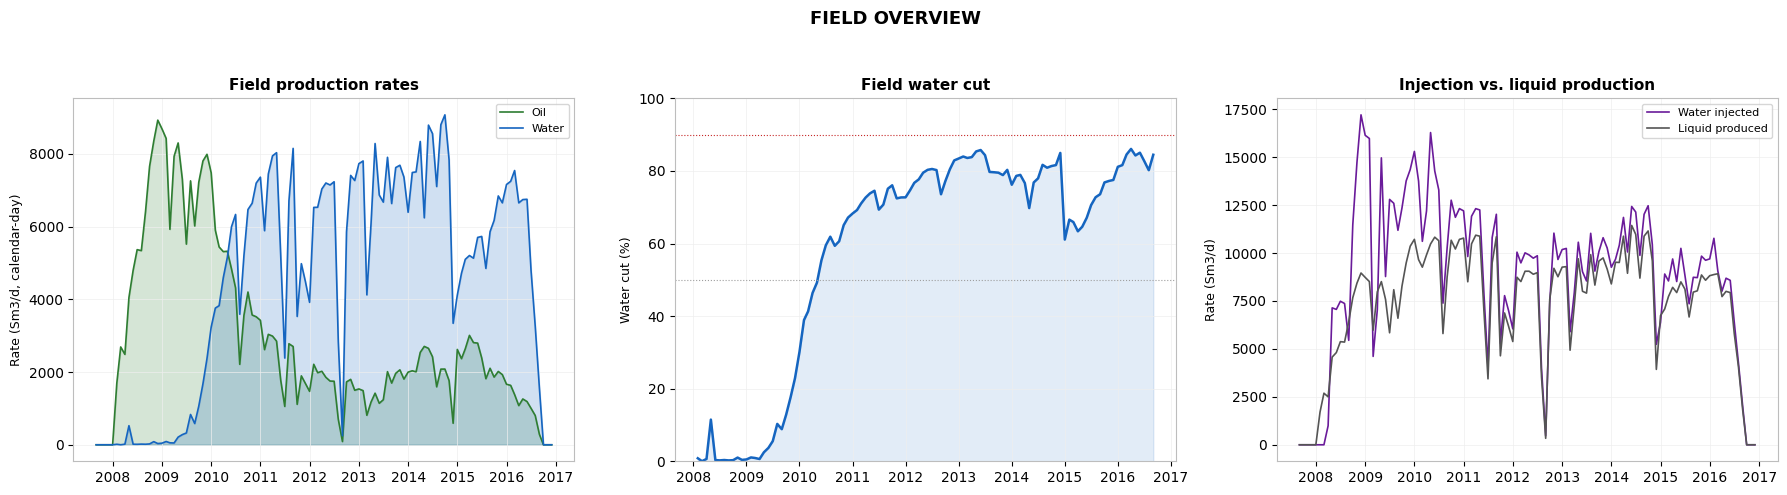

In [6]:
fig = field_overview(df, VOLUME_UNIT)
plt.show()

## 5. Water-cut heatmap

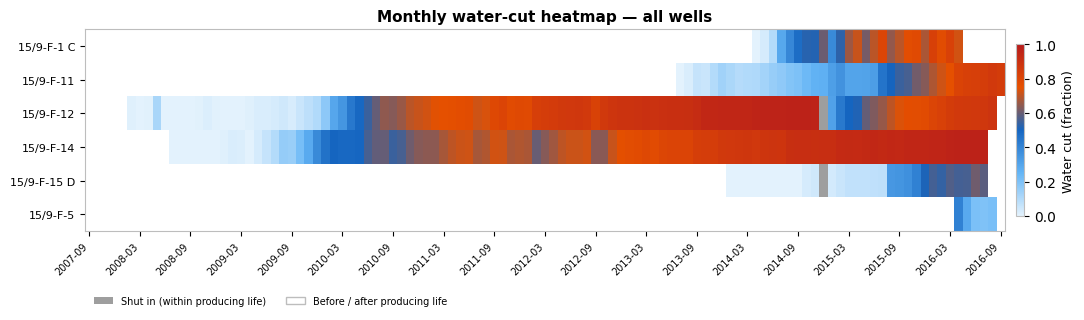

In [7]:
fig = wc_heatmap(prod)
plt.show()

## 6. WOR vs cumulative oil

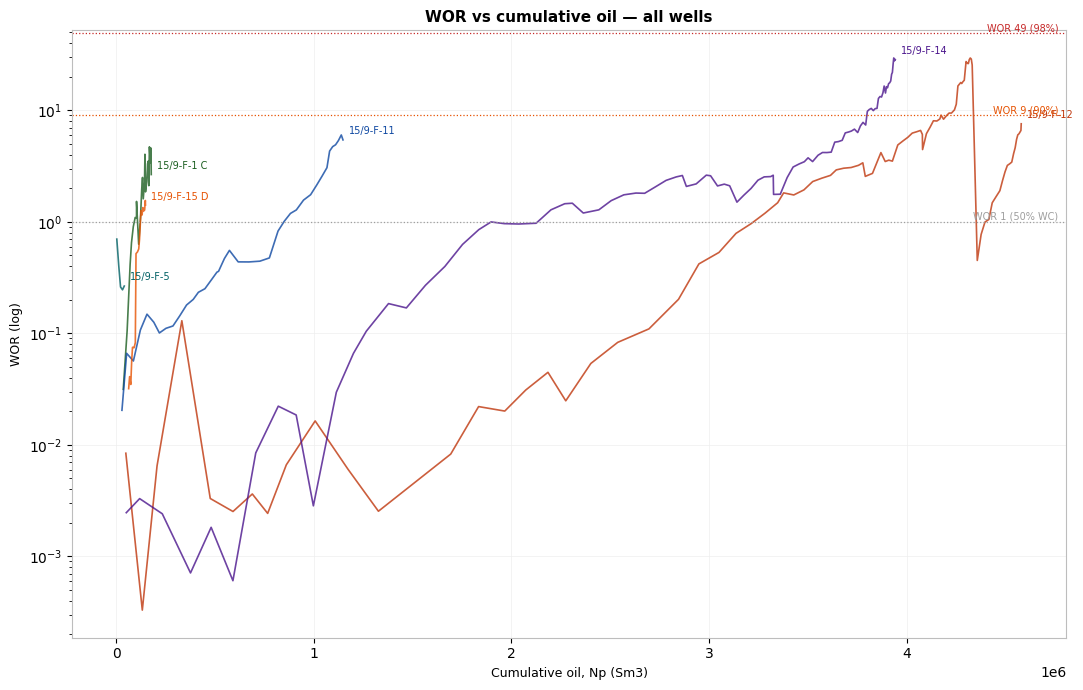

In [8]:
fig = wor_vs_cumoil(prod, VOLUME_UNIT)
plt.show()

## 7. Water cut vs cumulative oil

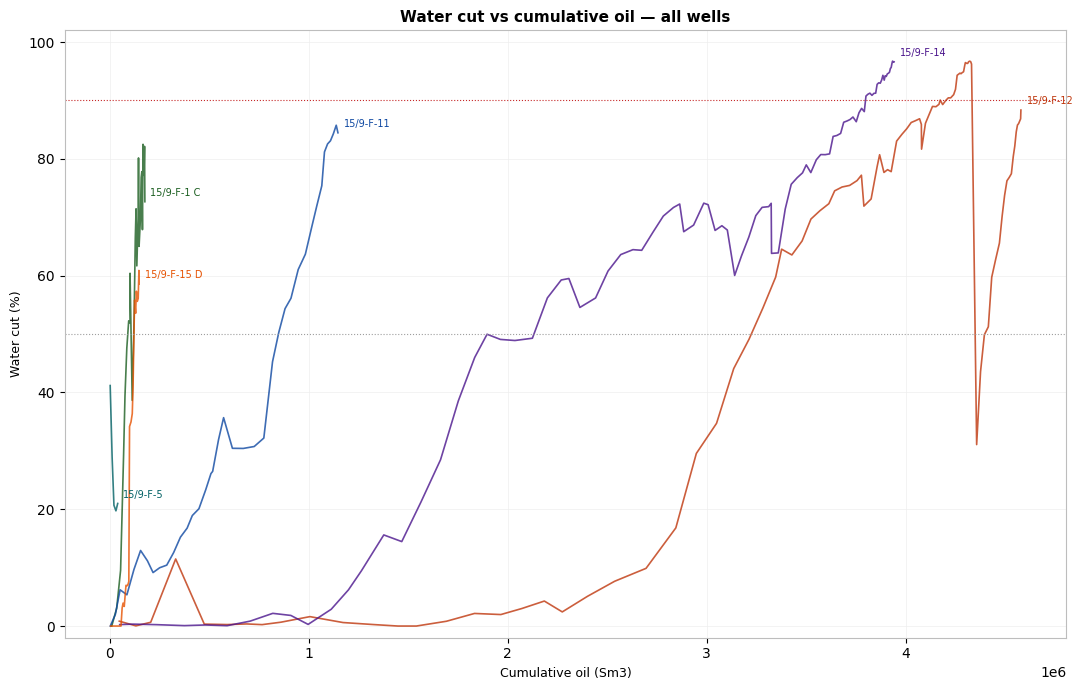

In [9]:
fig = wc_vs_cumoil(prod, VOLUME_UNIT)
plt.show()

## 8. Ershaghi–Abdou X-plot

Uses $X(f_w)=1/f_w+\ln[f_w/(1-f_w)]$. Points are shown only above the configured minimum water cut and below 100% to avoid the singularity.

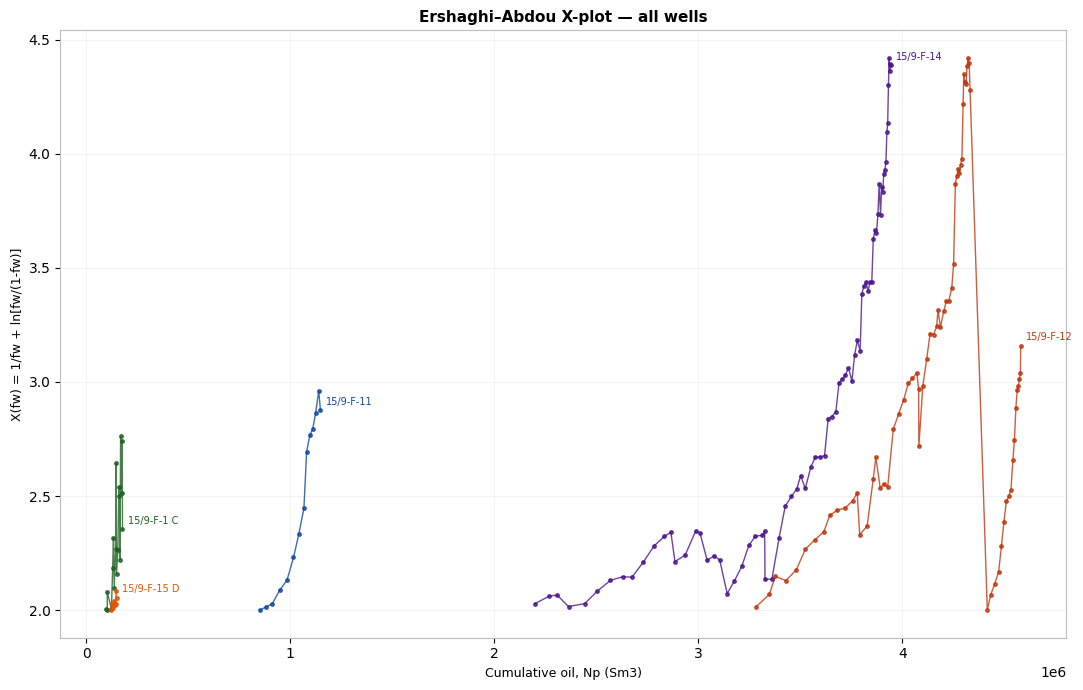

In [10]:
fig = ershaghi_xplot(prod, VOLUME_UNIT, minimum_fw=ERSHAGHI_MIN_FW)
plt.show()

## 9. Per-well diagnostics

Available wells: 15/9-F-1 C, 15/9-F-11, 15/9-F-12, 15/9-F-14, 15/9-F-15 D, 15/9-F-5


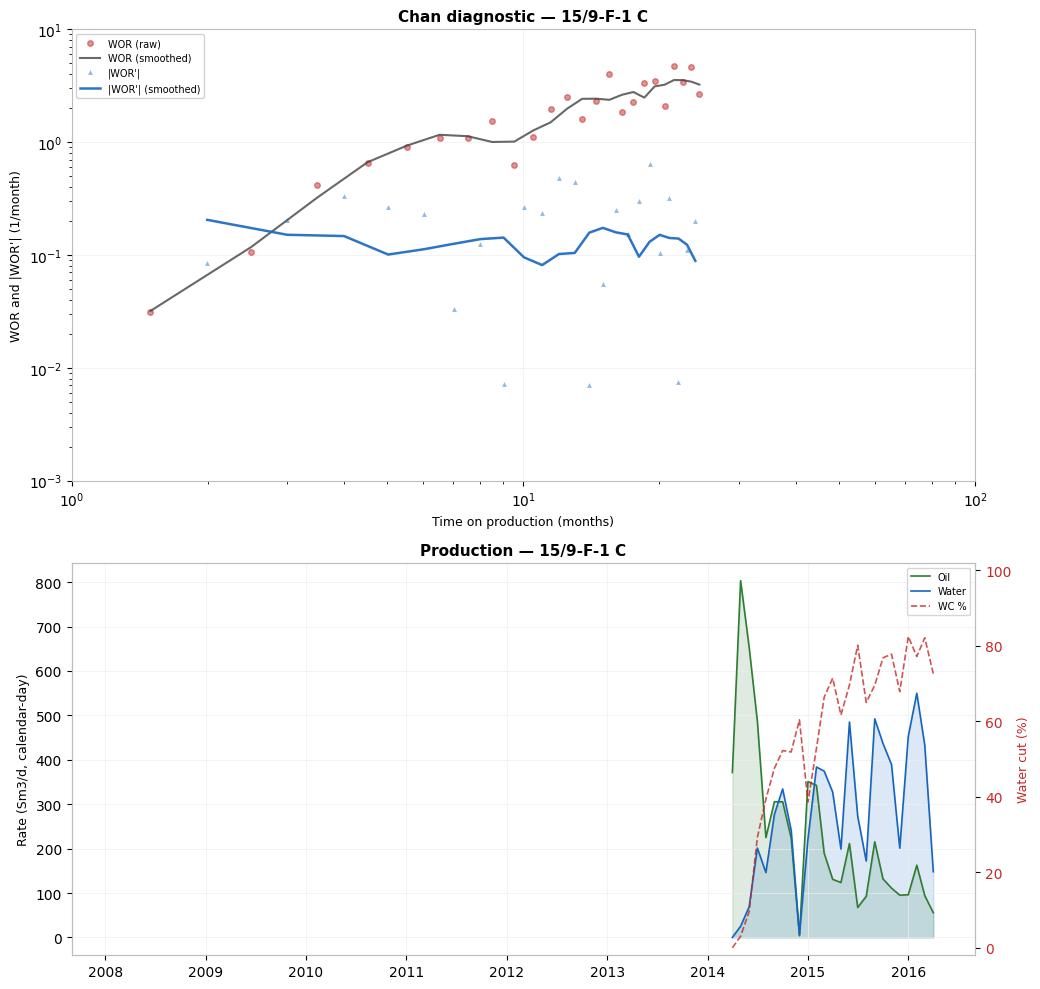

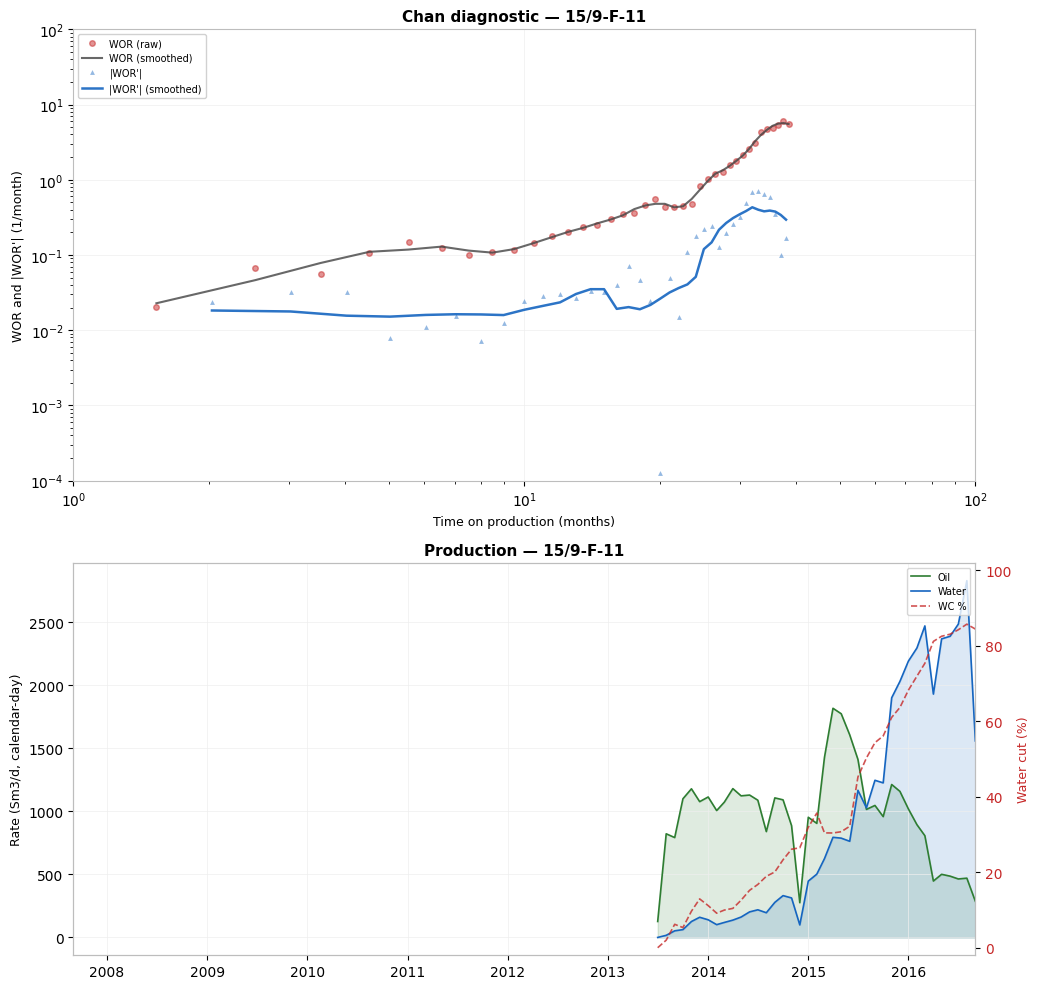

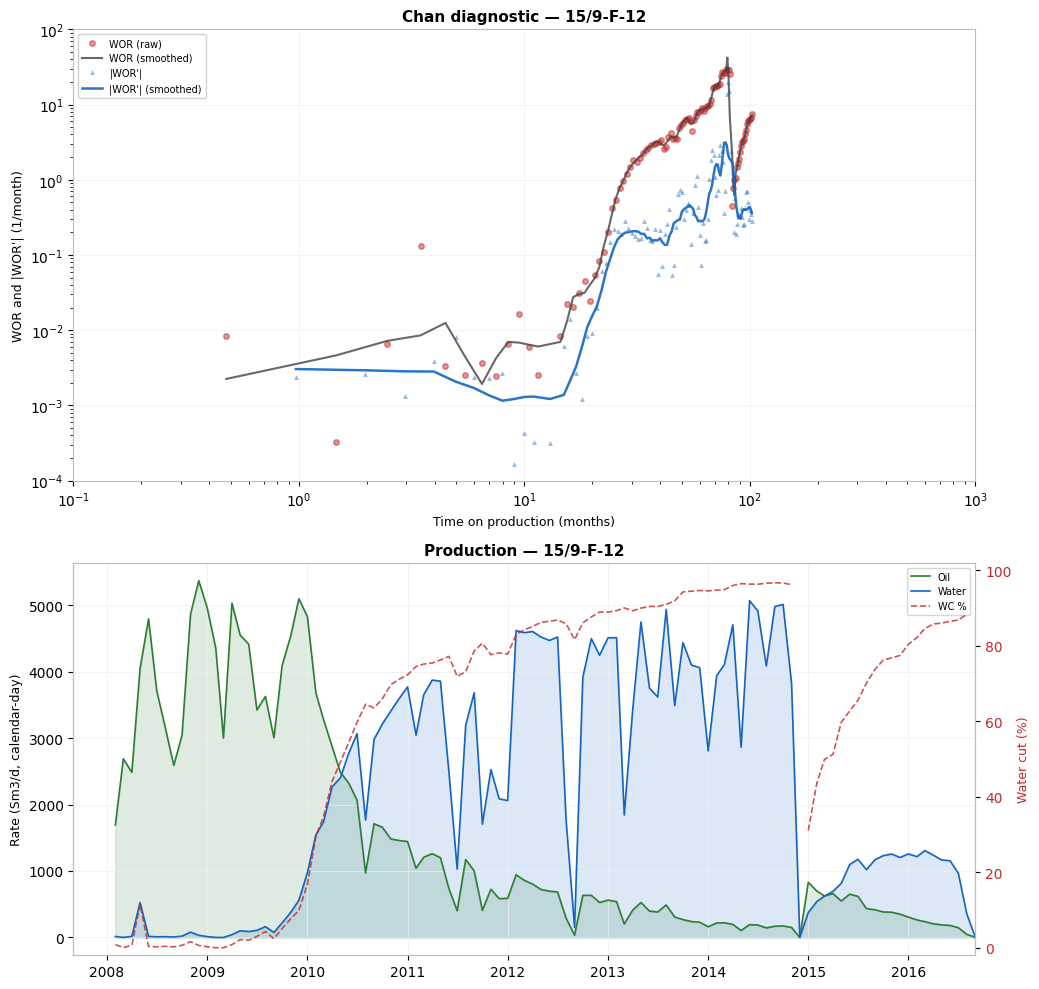

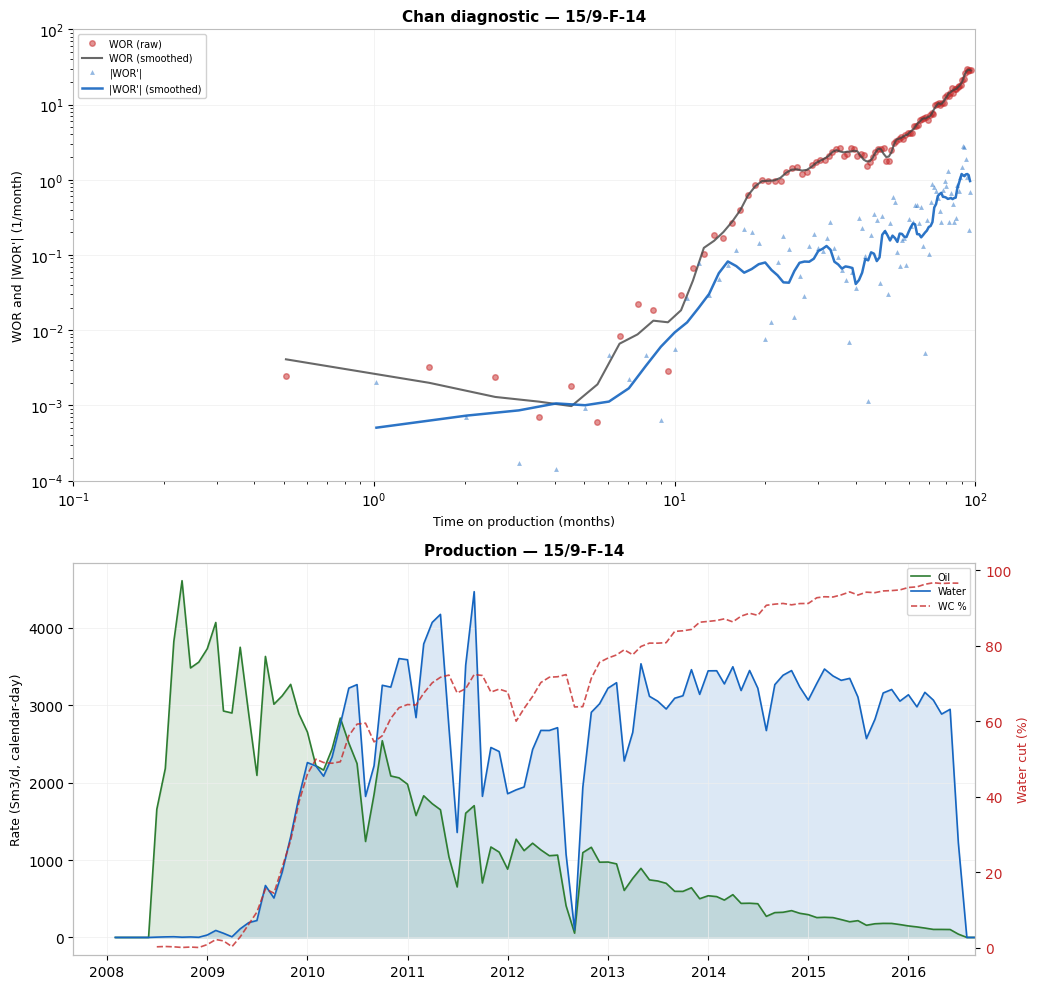

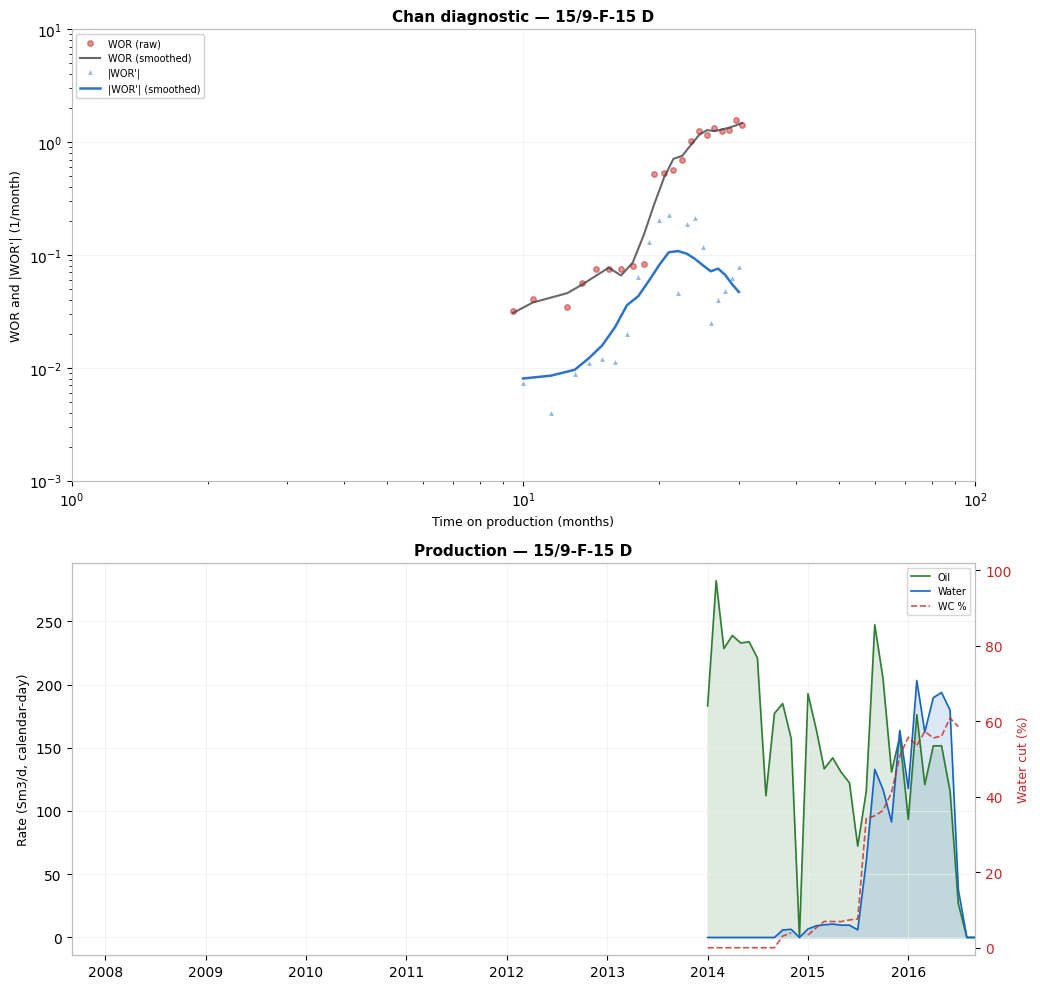

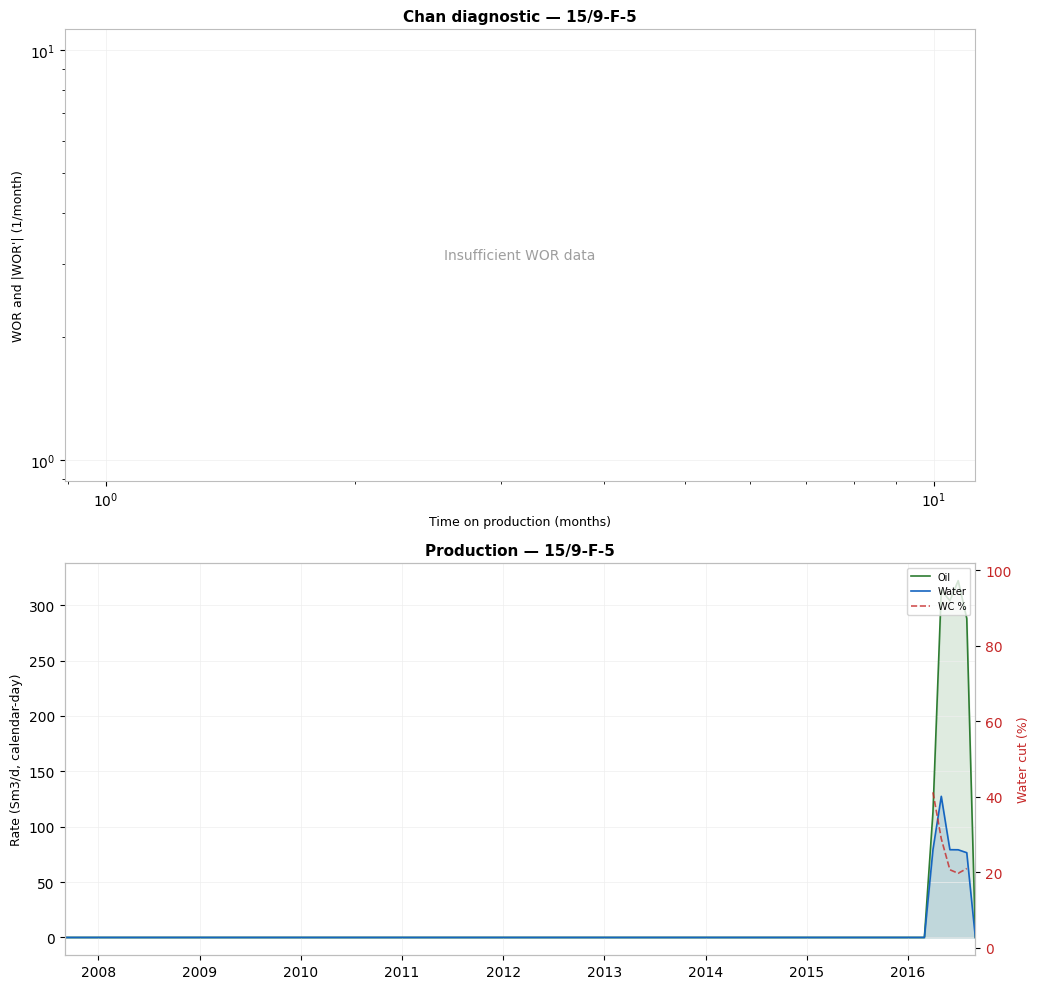

In [11]:
WELLS = sorted(prod.Well.unique())
print("Available wells:", ", ".join(WELLS))
SELECTED_WELLS = WELLS  # Or choose, e.g. ["15/9-F-12"]
FIELD_DATE_RANGE = (prod["Date"].min(), prod["Date"].max())
for well in SELECTED_WELLS:
    fig = well_diagnostics(prod, well, VOLUME_UNIT, date_range=FIELD_DATE_RANGE)
    plt.show()

## 10. Save figures (optional)

Figures are displayed above. Set `SAVE_FIGURES = False` to skip saving PNGs.

In [12]:
if SAVE_FIGURES:
    from re import sub
    figdir = OUTPUT_DIR / "figures"
    wellsdir = figdir / "wells"
    wellsdir.mkdir(parents=True, exist_ok=True)
    figure_builders = {
        'field_overview': lambda: field_overview(df, VOLUME_UNIT),
        'water_cut_heatmap': lambda: wc_heatmap(prod),
        'wor_vs_cumulative_oil': lambda: wor_vs_cumoil(prod, VOLUME_UNIT),
        'water_cut_vs_cumulative_oil': lambda: wc_vs_cumoil(prod, VOLUME_UNIT),
        'ershaghi_xplot': lambda: ershaghi_xplot(prod, VOLUME_UNIT, ERSHAGHI_MIN_FW),
    }
    for name, make in figure_builders.items():
        fig = make()
        fig.savefig(figdir / f'{name}.png', dpi=160, bbox_inches='tight')
        plt.close(fig)
    for well in SELECTED_WELLS:
        fig = well_diagnostics(prod, well, VOLUME_UNIT, date_range=FIELD_DATE_RANGE)
        filename = sub(r'[^A-Za-z0-9_.-]+', '_', well)
        fig.savefig(wellsdir / f'{filename}.png', dpi=160, bbox_inches='tight')
        plt.close(fig)
    print('Saved output to:', OUTPUT_DIR.resolve())
else:
    print('SAVE_FIGURES=False — no files written')

Saved output to: C:\python scripts\wbtdiag\results
